#### Isolation Forest ####

The contamination parameter is used as a threshold to make a final decision. Here's the process:

    Scoring: The Isolation Forest algorithm first runs and assigns an "anomaly score" to every single data point. Anomalies get lower scores; normal points (inliers) get higher scores.

    Thresholding: The algorithm then uses your contamination value to set a cutoff.

    Labeling: When you call the .predict() function:

        If you set contamination=0.1 (or 10%), the model will label the 10% of data points with the lowest anomaly scores as anomalies (label -1).

        It will label the other 90% as normal inliers (label 1).

In short, it's the parameter that tells the model, "After you've scored all the points, flag the worst [contamination]% as the anomalies."

In [1]:
import numpy as np
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

In [2]:
# Generate synthetic temperature data (normal + anomalies)
np.random.seed(42)
normal_temp = np.random.normal(loc=25, scale=2, size=1000)  # Normal operation
anomalous_temp = np.concatenate([
    np.random.normal(loc=25, scale=2, size=950),  # Normal
    np.random.uniform(low=40, high=60, size=50)   # Anomalies (spikes)
])

# Stack data
X = np.column_stack([normal_temp, anomalous_temp])

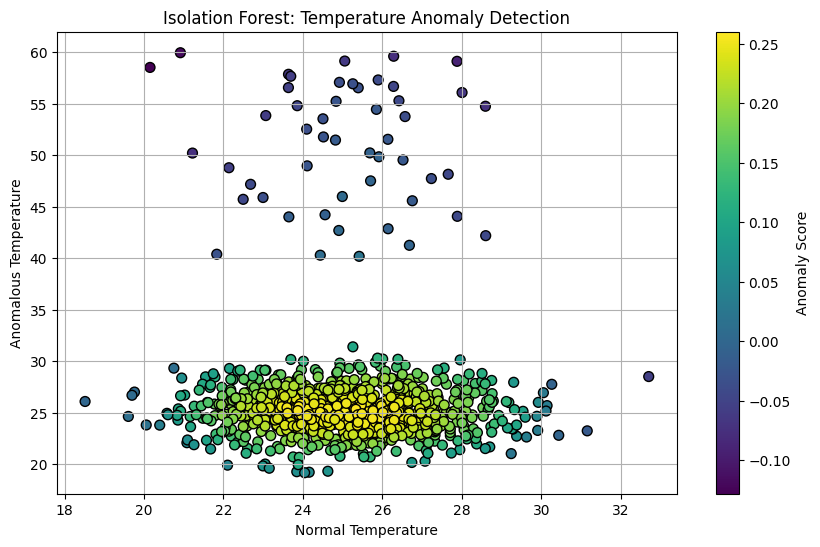

In [3]:
# Apply Isolation Forest
iso_forest = IsolationForest(contamination=0.05, random_state=42)
iso_forest.fit(X)
anomaly_scores = iso_forest.decision_function(X)
predictions = iso_forest.predict(X)

# Plot results
plt.figure(figsize=(10, 6))
plt.scatter(X[:, 0], X[:, 1], c=anomaly_scores, cmap='viridis', s=50, edgecolors='k')
plt.title("Isolation Forest: Temperature Anomaly Detection")
plt.xlabel("Normal Temperature")
plt.ylabel("Anomalous Temperature")
plt.colorbar(label='Anomaly Score')
plt.grid()
plt.show()
